# ****TP1 : Cadrage BI, processus métier et découverte des sources****

****1. QUESTION DE DÉPART****

**Comment passer d’un besoin de pilotage des ventes à des questions décisionnelles et à des sources réellement
exploitables ?**

=> Pour passer d’un besoin de pilotage des ventes à des questions décisionnelles, il faut d’abord bien définir les besoins et les objectifs de l’entreprise, en tenant compte de ce qui est réellement réalisable. Ensuite, on formule des questions décisionnelles dont les réponses permettront d’atteindre ces objectifs et d’aider la direction à prendre les bonnes décisions.

Avant toute manipulation,  les informations qu’un décideur pourrait chercher dans les données de vente sont :
* Les produits les plus vendus : Identifier les produits qui ont les quantités vendues les plus élevées*
* Les régions les plus rentables en chiffres d'affaires : Identifier les pays qui génèrent le chiffre d'affaires le plus élevé.
* L'évolution du vente dans le temp : savoir si les ventes augmentent ou diminuent selon le mois.
* Les clients les plus importants : Spécifier le genre du clients qui contribuent le plus au chiffre d'affaires.

****2. COMMENT ALLEZ-VOUS RAISONNER ?****

**Que devons-nous être capables de décider ou comprendre ?**
Nous devons être capables d'identifier les produits les plus vendus et les pays qui génèrent le chiffre d'affaires le plus élevé. Ces informations permettront à l'entreprise de se concentrer sur les produits les plus performants et les marchés les plus rentables afin d'améliorer ses décisions commerciales.

**Quelles questions peuvent être mesurées avec la source ?**
La source permet de répondre aux questions suivantes :
- Quel est le produit le plus vendu ?
- Quelle est l'évolution du chiffre d'affaires au cours des trois derniers mois ?
- Quel est le pays qui génère le chiffre d'affaires le plus élevé ?

**Quel est le processus métier observable dans le fichier ?**
Le processus métier représenté est le processus de vente. Il comprend les commandes des clients, les produits vendues, les quantités, les prix et la date de chaque commande.
Client → Passe une commande → L'entreprise vend → La facture est enregistrée.


**Quels champs semblent nécessaires pour répondre aux questions ?**
Les champs nécessaires pour répondre à ces questions sont :
- Description : pour identifier les produits.
- Quantity : pour connaître la quantité vendue de chaque produit.
- UnitPrice : pour calculer le chiffre d'affaires.
- InvoiceDate : pour analyser l'évolution du chiffre d'affaires au cours des trois derniers mois.
- Country : pour identifier le pays qui génère le chiffre d'affaires le plus élevé.

**Quelle limite de la source devez-vous signaler ?**
Dans Online Retail, on remarque souvent :
- des CustomerID manquants ;
- des factures annulées (InvoiceNo commence par C) ;
- des retours de produits (quantités négatives) ;
- quelques descriptions vides.


**Comment vérifierez-vous que votre inventaire est fidèle au fichier?**
Je vérifierai que mon inventaire correspond au fichier en comparant les noms des colonnes, leurs types de données et leur nombre avec ceux affichés par Pandas (df.columns, df.info()). Je contrôlerai également les dimensions du fichier (df.shape) afin de m'assurer que la source a été correctement chargée.

****3. MANIPULATION TECHNIQUE****

**a- Charger et inspecter la source**

In [1]:
import pandas as pd
df = pd.read_excel('/kaggle/input/datasets/mohammedchakourhh/one-retail/Online Retail.xlsx')

print("Les dimensions du dataset sont ", df.shape)

Les dimensions du dataset sont  (541909, 8)


In [2]:
print("Les colonnes existantes sont : ", df.columns.tolist())

Les colonnes existantes sont :  ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [3]:
print("Les 5 premiers lignes ", df.head())

Les 5 premiers lignes    InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  


In [10]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

**QUESTION D’ANALYSE**

**Quelles informations sont réellement disponibles et lesquelles ne
doivent pas être inventées ?**
Les informations disponibles sont le numéro de facture (InvoiceNo), le code et la description du produit (StockCode, Description), la quantité vendue (Quantity), la date de la commande (InvoiceDate), le prix unitaire (UnitPrice), l'identifiant du client (CustomerID) et le pays (Country). En revanche, le fichier ne contient pas d'informations comme l'âge du clients, leur sexe et la catégorie des produits. Ces informations ne doivent donc pas être inventées.

**b- Profiler les champs utiles au cadrage**

**i- Directive technique**

In [11]:
print("Le type de chaque colonne:")
print(df.dtypes)
print("Nombres de valeurs manquantes pour chaque variable :")
print(df.isnull().sum())
print(df.describe().T)

Le type de chaque colonne:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object
Nombres de valeurs manquantes pour chaque variable :
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
                count                           mean                  min  \
Quantity     541909.0                        9.55225             -80995.0   
InvoiceDate    541909  2011-07-04 13:34:57.156386048  2010-12-01 08:26:00   
UnitPrice    541909.0                       4.611114            -11062.06   
CustomerID   406829.0                    15287.69057              12346.0   

                             25%                  50%                  75%  \
Quantity     

In [12]:
print(df.columns)
df1 = pd.DataFrame(columns=['Colonne', 'Type', 'Val_manqu'])
df1['Colonne'] = df.columns
df1['Type'] = df.dtypes.values
df1['Val_manqu'] = df.isnull().sum().values
print(df1)


Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')
       Colonne            Type  Val_manqu
0    InvoiceNo          object          0
1    StockCode          object          0
2  Description          object       1454
3     Quantity           int64          0
4  InvoiceDate  datetime64[ns]          0
5    UnitPrice         float64          0
6   CustomerID         float64     135080
7      Country          object          0


CustomerID → Trpo de valeurs manquantes(135080).
Description → quelques valeurs manquantes(1454).

**QUESTION D’ANALYSE**
**Une valeur manquante est-elle automatiquement une erreur métier ?**
Non. Une valeur manquante n'est pas forcément une erreur métier. Car dans la dataset beaucoup de lignes n'ont pas du CustomerID, cela peut signifier que un achat effectué par un client non enregistré.

**c- Relier les champs au processus de vente**

Vente(InvoiceNo'Numero de facture') → Produit(StockCode, Description) → Date de vente(InvoiceDate) → Pays(Country) → Client(Customer ID)

**QUESTION D’ANALYSE**

***Quelle information permet d’identifier une commande et quelleinformation décrit le produit ?***
La commande est identifiée par InvoiceNo qui représente le numéro unique de la facture(commande)
Le produit est décrit par les champs StockCode, qui représente son code, et Description, qui contient son nom ou sa description.

****4. QUESTIONS DÉCISIONNELLES****

**QUESTION1 :** Comment les ventes évoluent-t-elles au cours du temps (par mois) ?

Colonnes utilisées pour répondre à la question :
- InvoiceDate
- Quantity
- UnitPrice

InvoiceDate
2010-12     823746.140
2011-01     691364.560
2011-02     523631.890
2011-03     717639.360
2011-04     537808.621
2011-05     770536.020
2011-06     761739.900
2011-07     719221.191
2011-08     759138.380
2011-09    1058590.172
2011-10    1154979.300
2011-11    1509496.330
2011-12     638792.680
Freq: M, Name: Revenue, dtype: float64


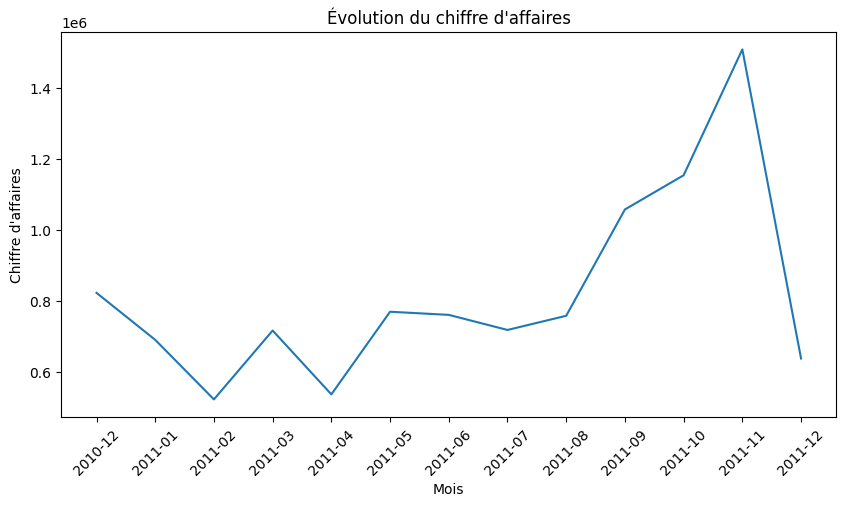

In [37]:
import matplotlib.pyplot as plt

# Conserver les lignes dont la quantité est > 0
df_copy = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)].copy() 

#Supprimer les lignes dont la commande est canceled
df_copy = df_copy[~df_copy["InvoiceNo"].str.startswith("C", na=False)]

# print(df_copy["Quantity"][df["Quantity"] < 0].count())
df_copy["Revenue"] = df_copy["Quantity"] * df_copy["UnitPrice"]

monthly_sales = (
    df_copy.groupby(df_copy["InvoiceDate"].dt.to_period("M"))["Revenue"]
      .sum()
)
print(monthly_sales)

monthly_sales.index = monthly_sales.index.astype(str)

plt.figure(figsize=(10,5))
plt.plot(monthly_sales.index, monthly_sales.values)
plt.title("Évolution du chiffre d'affaires")
plt.xlabel("Mois")
plt.ylabel("Chiffre d'affaires")
plt.xticks(rotation=45)
plt.show()

**QUESTION 2**
Quels sont les 10 produits qui génèrent le plus de chiffre d'affaires ?

Les colonnes utilisées pour répondre à cette question:
- Description
- Quantity
- UnitP

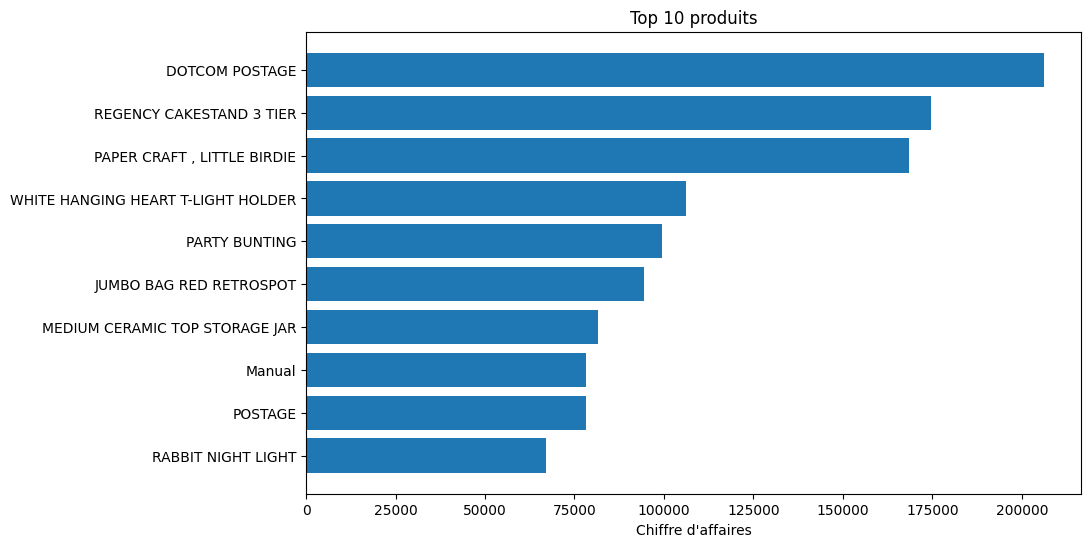

In [38]:
top_produits = (
    df_copy.groupby('Description')["Revenue"].sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10,6))
plt.barh(top_produits.index, top_produits.values)
plt.title("Top 10 produits")
plt.xlabel("Chiffre d'affaires")
plt.gca().invert_yaxis()
plt.show()

**QUESTION 3 :**
Quels pays génèrent le chiffre d'affaires le plus élevé ?

Colonnes utilisées :
- Country
- Quantity
- UnitPrice

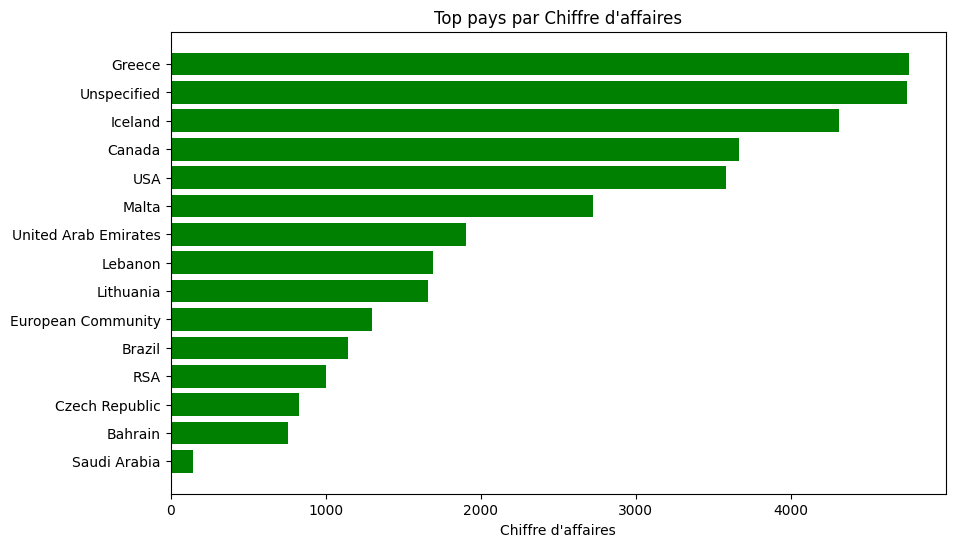

In [39]:
Top_Country = (
    df_copy.groupby('Country')['Revenue'].sum()
    .sort_values(ascending=True)
    .head(15)
)

plt.figure(figsize=(10, 6))
plt.barh(Top_Country.index, Top_Country.values, color ='green')
plt.title("Top pays par Chiffre d'affaires")
plt.xlabel("Chiffre d'affaires")
plt.show()

**QUESTION 4 :**
Quelle est la répartition des commandes entre les clients identifiés et les clients inconnus ?
Colonne utilisée :
- CustomerID

0         Client identifié
1         Client identifié
2         Client identifié
3         Client identifié
4         Client identifié
                ...       
541904    Client identifié
541905    Client identifié
541906    Client identifié
541907    Client identifié
541908    Client identifié
Name: CustomerID, Length: 530104, dtype: object
CustomerID
Client identifié    397884
Client inconnu      132220
Name: count, dtype: int64


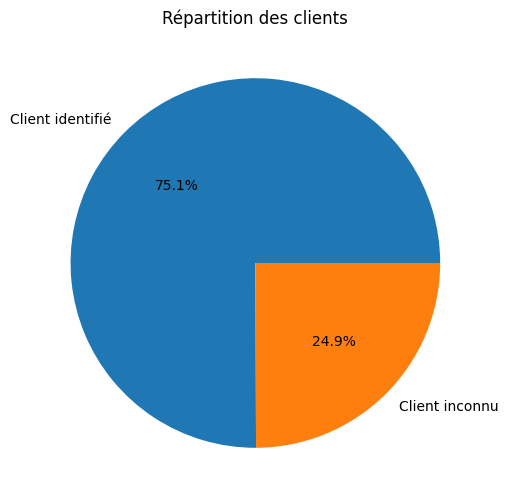

In [40]:
customer_type = df_copy['CustomerID'].isnull().replace({
    True: "Client inconnu",
    False:"Client identifié"
})

print(customer_type)

counts = customer_type.value_counts()
print(counts)

plt.figure(figsize=(6,6))
plt.pie(counts.values,
        labels=counts.index,
        autopct="%1.1f%%")
plt.title("Répartition des clients")
plt.show()